In [1]:
from google.colab import drive
drive.mount('/content/drive/')

ModuleNotFoundError: No module named 'google.colab'

In [2]:
%cd /content/drive/MyDrive/ML_Samples

[Errno 2] No such file or directory: '/content/drive/MyDrive/ML_Samples'
/home/hosseini/Desktop/CNN/PreProcessing_Motif


In [4]:
!pip install tensorly

Defaulting to user installation because normal site-packages is not writeable


In [5]:
from scipy.signal import butter, lfilter
from scipy import signal
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
import h5py
import os.path
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN
from tensorly.decomposition import parafac
from tensorly.cp_tensor import cp_to_tensor
import tensorly as tl
from scipy.signal import welch
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
#import librosa.display
# !pip install tensorly
# from kneed import KneeLocator
# !pip install numpy==1.21.6 scipy==1.7.3
# pip install --upgrade tensorly

2026-04-29 18:31:54.566223: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-04-29 18:31:54.567782: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-04-29 18:31:54.570794: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-04-29 18:31:54.580523: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777501914.596611 1699203 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777501914.60

In [6]:
data_path = "/home/hosseini/Desktop/2024/CNN_samples"
file_xtrain_baseline = data_path + "/2024-01-24mPFC_Slice1_LC_to_mPFC_hsyn_ChR2_eYFP_Vehicle_KO__0005.h5"
################################################################### Baseline
with h5py.File(file_xtrain_baseline, 'r') as hdf:
    dt1 = hdf.get('Data/Recording_0/AnalogStream/Stream_0')
    dt1_items = list(dt1.items())
    ChannelData_baseline = np.array(dt1.get('ChannelData'))
    print(ChannelData_baseline.shape)

sf = 20000 # sampling requency
print(f'time recorded in min: {((len(ChannelData_baseline[1])/sf)/60)}')

(60, 6060000)
time recorded in min: 5.05


In [7]:
def filter_dataLFP(data, low, sf, order=2):
    # Determine Nyquist frequency
    nyq = sf/2

    # Set bands
    low = low/nyq
#     high = high/nyq

    # Calculate coefficients
    b, a = butter(order, low, btype='low')

    # Filter signal
    filtered_data = lfilter(b, a, data)



def filter_data(data, low, high, sf, order=2):
    # Determine Nyquist frequency
    nyq = sf/2

    # Set bands
    low = low/nyq
    high = high/nyq

    # Calculate coefficients
    b, a = butter(order, [low, high], btype='bandpass',)

    # Filter signal
    filtered_data = lfilter(b, a, data)

    return filtered_data
##This function always calculates the downsampling factor as an integer and applies
#decimation in steps of up to 10 to avoid excessive decimation in one step (which can cause aliasing).
def downsample_data(data, sf, target_sf):
    # Calculate the initial downsampling factor
    factor = int(sf / target_sf)

    # Check if downsampling is necessary
    if factor < 1:
        raise ValueError("Target sampling frequency must be less than original sampling frequency.")

    # Downsample using multiple steps if necessary
    data_down = data
    while factor > 1:
        # Apply decimation in chunks to avoid excessive decimation
        step_factor = min(factor, 10)  # Decimate in steps of max 10 to avoid aliasing
        data_down = signal.decimate(data_down, step_factor, ftype='fir')
        sf = sf / step_factor  # Update the sampling rate after each decimation
        factor = int(sf / target_sf)  # Recalculate the factor for the next iteration

    return data_down, int(sf)

In [8]:
unwanted_num = [14,12,
               ]# channels to be removed


# List of numbers with corresponding indices as shown in the image
numbers_dict = {
    54: 0, 56: 1, 55: 2, 46: 3, 45: 4, 44: 5, 36: 6, 35: 7, 34: 8, 26: 9,
    16: 10, 25: 11, 15: 12, 24: 13, 14: 14, 13: 15, 23: 16, 12: 17, 22: 18,
    11: 19, 21: 20, 33: 21, 32: 22, 31: 23, 43: 24, 42: 25, 41: 26, 52: 27,
    51: 28, 53: 29, 63: 30, 61: 31, 62: 32, 71: 33, 72: 34, 73: 35, 81: 36,
    82: 37, 83: 38, 91: 39, 101: 40, 92: 41, 102: 42, 93: 43, 103: 44,
    104: 45, 94: 46, 105: 47, 95: 48, 106: 49, 96: 50, 84: 51, 85: 52,
    86: 53, 74: 54, 75: 55, 76: 56, 65: 57, 66: 58, 64: 59
}

# Function to get corresponding indices, excluding unwanted numbers
def get_corresponding_values(selected_nums):
    filtered_values = [numbers_dict[num] for num in selected_nums if num not in unwanted_num and num in numbers_dict]
    return filtered_values


PrL_L5 = get_corresponding_values([
#     11,21,31,
#     41,51,61,71,81,91,101,
#     12,22,32,
#     42,52,62,72,92,102,
#     13,23,43,
    53,63,73,83,93,103,
#     24,34,
    54,64,74,84,94,104,
#     15,25,35,
    45,55,65,75,85,95,105,
#     16,26,36,
    46,56,66,76,86,96,106,
])

PrL_L23 = get_corresponding_values([
#     11,21,31,
    41,51,61,71,81,91,101,
#     12,22,32,
    42,52,62,72,92,102,
#     13,23,43,
#     53,63,73,83,93,103,
#     24,34,
#     54,64,74,84,94,104,
#     15,25,35,
#     45,55,65,75,85,95,105,
#     16,26,36,
#     46,56,66,76,86,96,106,
])




IL_L5 = get_corresponding_values([
#     11,21,31,
#     41,51,61,71,81,91,101,
#     12,22,32,
#     42,52,62,72,92,102,
    13,23,43,
#     53,63,73,83,93,103,
    24,34,
#     54,64,74,84,94,104,
    15,25,35,
#     45,55,65,75,85,95,105,
    16,26,36,
#     46,56,66,76,86,96,106,
])

IL_L23 = get_corresponding_values([
    11,21,31,
#     41,51,61,71,81,91,101,
    12,22,32,
#     42,52,62,72,92,102,
#     13,23,43,
#     53,63,73,83,93,103,
#     24,34,
#     54,64,74,84,94,104,
#     15,25,35,
#     45,55,65,75,85,95,105,
#     16,26,36,
#     46,56,66,76,86,96,106,
])
print(PrL_L23, PrL_L5, IL_L23, IL_L5)

[26, 28, 31, 33, 36, 39, 40, 25, 27, 32, 34, 41, 42] [29, 30, 35, 38, 43, 44, 0, 59, 54, 51, 46, 45, 4, 2, 57, 55, 52, 48, 47, 3, 1, 58, 56, 53, 50, 49] [19, 20, 23, 18, 22] [15, 16, 24, 13, 8, 12, 11, 7, 10, 9, 6]


In [11]:
# =========================================================
# IMPORTS
# =========================================================
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorly as tl
from tensorly.decomposition import parafac

# =========================================================
# PARAMETERS
# =========================================================
sf = 20000
target_sf = 10000

bands = {
    "GBO": (30, 100),
    "HFO": (120, 200)
}

window_size = 1000
stride = 500

# =========================================================
# NOTCH FILTER (60 Hz)
# =========================================================
f0 = 60.0
Q = 30
w0 = f0 / (target_sf / 2)
b_notch, a_notch = signal.iirnotch(w0, Q)

# =========================================================
# SPIKE DETECTION (ROBUST)
# =========================================================
def detect_spikes(data, z_thresh=4.0, refractory_ms=2, fs=10000, max_amp=None):

    data_z = (data - np.mean(data)) / (np.std(data) + 1e-12)

    crossings = np.where(data_z > z_thresh)[0]

    if len(crossings) == 0:
        return np.array([])

    refractory_samples = int((refractory_ms / 1000) * fs)

    spikes = []
    last_spike = -np.inf

    for idx in crossings:
        if idx - last_spike > refractory_samples:

            if max_amp is None or data[idx] < max_amp:
                spikes.append(idx)
                last_spike = idx

    return np.array(spikes)

# =========================================================
# BUILD SPIKE MATRIX (channels × time)
# =========================================================
def build_spike_matrix(dataset, fs=10000, z_thresh=4.0):

    spike_matrix = []

    for ch in range(len(dataset)):

        data = dataset[ch].ravel()

        spikes = detect_spikes(data, z_thresh=z_thresh, fs=fs)

        train = np.zeros(len(data))
        train[spikes.astype(int)] = 1

        spike_matrix.append(train)

    return np.array(spike_matrix)

# =========================================================
# BINNING FOR CP TENSOR
# =========================================================
def bin_spike_matrix(spike_matrix, window=1000, stride=500):

    n_ch, n_t = spike_matrix.shape
    out = []

    for ch in range(n_ch):

        vec = []

        for start in range(0, n_t - window, stride):

            segment = spike_matrix[ch, start:start+window]

            rate = np.sum(segment) / window

            vec.append(rate)

        out.append(vec)

    return np.array(out)

# =========================================================
# PREPROCESSING (YOUR ORIGINAL PIPELINE)
# =========================================================
def preprocess_layer(ChannelData_baseline, channel_list):

    clean = []

    for ch in channel_list:

        data = ChannelData_baseline[ch].ravel()

        # bandpass LFP
        data = filter_data(data, low=1, high=500, sf=sf)

        # downsample
        lfp, _ = downsample_data(data, sf=sf, target_sf=target_sf)

        # notch filter
        lfp = signal.lfilter(b_notch, a_notch, lfp)

        clean.append(lfp)

    return np.array(clean)

# =========================================================
# LOAD DATA (YOU ALREADY HAVE THESE)
# =========================================================
PrL23_data = preprocess_layer(ChannelData_baseline, PrL_L23)
PrL5_data  = preprocess_layer(ChannelData_baseline, PrL_L5)

# =========================================================
# LFP → SPIKES
# =========================================================
PrL23_spikes = build_spike_matrix(PrL23_data, fs=target_sf, z_thresh=4.0)
PrL5_spikes  = build_spike_matrix(PrL5_data, fs=target_sf, z_thresh=4.0)

# =========================================================
# SPIKES → FIRING RATE TENSOR
# =========================================================
PrL23_tensor = bin_spike_matrix(PrL23_spikes, window_size, stride)
PrL5_tensor  = bin_spike_matrix(PrL5_spikes, window_size, stride)

# =========================================================
# CP DECOMPOSITION (OPTIONAL STEP)
# =========================================================
def run_cp(tensor, ranks=range(1,6)):

    tensor_tl = tl.tensor(tensor)

    errors = []

    for r in ranks:

        try:
            factors = parafac(tensor_tl, rank=r)
            recon = tl.cp_to_tensor(factors)

            err = tl.norm(tensor_tl - recon) / (tl.norm(tensor_tl) + 1e-12)

            errors.append(err)

        except:
            errors.append(np.inf)

    best_r = list(ranks)[np.argmin(errors)]

    final_model = parafac(tensor_tl, rank=best_r)

    return final_model, best_r

# =========================================================
# RUN CP
# =========================================================
model_L23, rank_L23 = run_cp(PrL23_tensor)
model_L5,  rank_L5  = run_cp(PrL5_tensor)

print("Optimal ranks:")
print("L23:", rank_L23)
print("L5 :", rank_L5)

# =========================================================
# OUTPUT TENSORS READY FOR ANALYSIS
# =========================================================
print("PrL23 tensor shape:", PrL23_tensor.shape)
print("PrL5 tensor shape :", PrL5_tensor.shape)

Optimal ranks:
L23: 5
L5 : 5
PrL23 tensor shape: (13, 6058)
PrL5 tensor shape : (26, 6058)


PrL_L23 (spikes) shape: (13, 6058)
PrL_L23 (spikes) optimal rank: 5
PrL_L5 (spikes) shape: (26, 6058)
PrL_L5 (spikes) optimal rank: 5


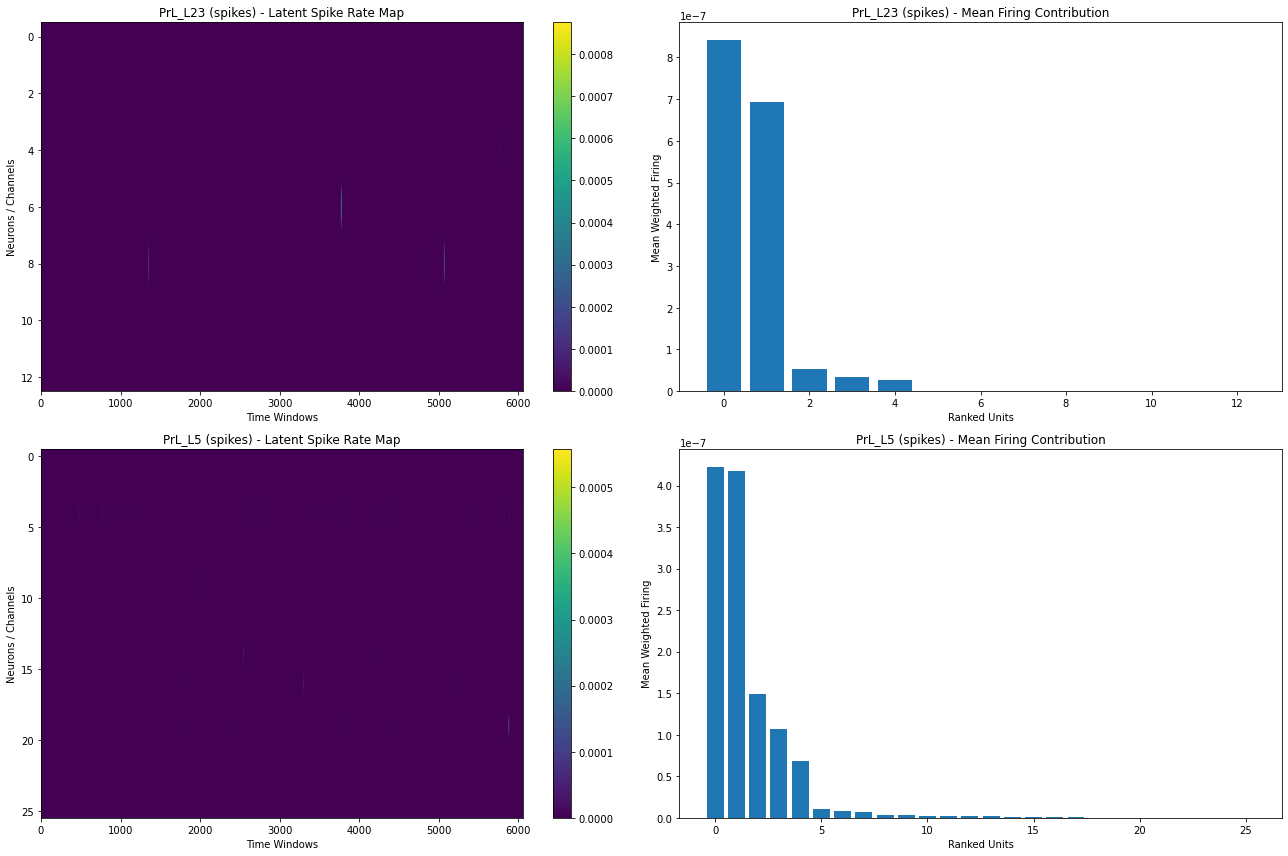

In [12]:
# =========================================================
# IMPORTS
# =========================================================
import numpy as np
import tensorly as tl
from tensorly.decomposition import parafac
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# =========================================================
# PARAMETERS
# =========================================================
datasets = [PrL23_spikes, PrL5_spikes]
dataset_names = ['PrL_L23 (spikes)', 'PrL_L5 (spikes)']

window_size = 1000   # samples (adjust to your binning)
stride = 500

ranks = range(1, 6)

# =========================================================
# SPIKE COUNT FEATURE EXTRACTION
# =========================================================
def compute_firing_rate_matrix(spike_data, window_size, stride):

    n_channels, n_time = spike_data.shape
    out = []

    for ch in range(n_channels):

        channel_vec = []

        for start in range(0, n_time - window_size, stride):

            window = spike_data[ch, start:start+window_size]

            # spike count → firing rate
            rate = np.sum(window) / window_size

            channel_vec.append(rate)

        out.append(channel_vec)

    return np.array(out)

# =========================================================
# MAIN PIPELINE
# =========================================================
combined_list = []

fig, axs = plt.subplots(2, 2, figsize=(18, 12))

for i, (data, name) in enumerate(zip(datasets, dataset_names)):

    # -------------------------------
    # 1. FIRING RATE MATRIX
    # -------------------------------
    fr_matrix = compute_firing_rate_matrix(data, window_size, stride)

    print(f"{name} shape: {fr_matrix.shape}")

    # -------------------------------
    # 2. TENSOR
    # -------------------------------
    tensor_data = tl.tensor(fr_matrix)

    n_data = np.prod(tensor_data.shape)

    # -------------------------------
    # 3. RANK SELECTION (simple reconstruction error)
    # -------------------------------
    errors = []

    for r in ranks:
        try:
            factors = parafac(tensor_data, rank=r)

            recon = tl.cp_to_tensor(factors)

            err = tl.norm(tensor_data - recon) / (tl.norm(tensor_data) + 1e-12)

            errors.append(err)

        except:
            errors.append(np.inf)

    optimal_rank = ranks[np.argmin(errors)]

    print(f"{name} optimal rank: {optimal_rank}")

    # -------------------------------
    # 4. CP DECOMPOSITION
    # -------------------------------
    try:
        factors = parafac(tensor_data, rank=optimal_rank)

        spatial_weights = np.mean(np.abs(factors.factors[0]), axis=1)
        temporal_weights = np.mean(np.abs(factors.factors[1]), axis=1)

        combined = fr_matrix * spatial_weights[:, np.newaxis]

    except:
        print(f"CP failed for {name}, using raw FR")
        combined = fr_matrix

    combined_list.append(combined)

    # -------------------------------
    # 5. VISUALIZATION
    # -------------------------------

    im = axs[i, 0].imshow(
        combined,
        aspect='auto',
        cmap='viridis'
    )

    axs[i, 0].set_title(f"{name} - Latent Spike Rate Map")
    axs[i, 0].set_xlabel("Time Windows")
    axs[i, 0].set_ylabel("Neurons / Channels")
    plt.colorbar(im, ax=axs[i, 0])

    # mean activity ranking
    mean_activity = np.mean(combined, axis=1)
    order = np.argsort(mean_activity)[::-1]

    axs[i, 1].bar(
        range(len(order)),
        mean_activity[order]
    )

    axs[i, 1].set_title(f"{name} - Mean Firing Contribution")
    axs[i, 1].set_xlabel("Ranked Units")
    axs[i, 1].set_ylabel("Mean Weighted Firing")

plt.tight_layout()
plt.show()

# =========================================================
# OUTPUTS
# =========================================================
combined_PrL23_spikes = combined_list[0]
combined_PrL5_spikes = combined_list[1]

In [9]:
########################################################## PrL Layer 2/3
from scipy import signal
from scipy.signal import butter, lfilter
sf = 20000 # sampling frequency
target_sf = 10000 # target frequency for downsampling
f0 = 60.0  # Frequency to be removed from signal (Hz)
w0 = f0/(target_sf/2)  # Normalized Frequency
Q = 30 # Quality factor
# Design notch filter
b, a = signal.iirnotch(w0, Q)

start = 0

################################################### baseline
end = int(len(ChannelData_baseline[0])/sf)
clean_data_vehicle1 = []

for chanlNo in (PrL_L23):
    data = ChannelData_baseline[chanlNo].ravel()
    spike_data = filter_data(data[start*sf:end*sf], low=1, high= 500, sf=sf) # Band pass filter the data for LFP analysis
    # Now we use the above function to downsample the signal.
    lfp_data, sf_lfp = downsample_data(spike_data, sf=sf, target_sf=target_sf)
    clean_data_vehicle1.append(signal.lfilter(b, a, lfp_data))

########################################################## PrL Layer 5
from scipy import signal
from scipy.signal import butter, lfilter
sf = 20000 # sampling frequency
target_sf = 10000 # target frequency for downsampling
f0 = 60.0  # Frequency to be removed from signal (Hz)
w0 = f0/(target_sf/2)  # Normalized Frequency
Q = 30 # Quality factor
# Design notch filter
b, a = signal.iirnotch(w0, Q)

start = 0

################################################### baseline
end = int(len(ChannelData_baseline[0])/sf)
clean_data_vehicle2 = []

for chanlNo in (PrL_L5):
    data = ChannelData_baseline[chanlNo].ravel()
    spike_data = filter_data(data[start*sf:end*sf], low=1, high= 500, sf=sf) # Band pass filter the data for LFP analysis
    # Now we use the above function to downsample the signal.
    lfp_data, sf_lfp = downsample_data(spike_data, sf=sf, target_sf=target_sf)
    clean_data_vehicle2.append(signal.lfilter(b, a, lfp_data))
    
PrL23_data = np.array(clean_data_vehicle1)
PrL5_data = np.array(clean_data_vehicle2)

In [10]:
PrL23_data = np.array(clean_data_vehicle1)
PrL5_data = np.array(clean_data_vehicle2)

In [10]:
PrL23_data.shape

(13, 3030000)

In [11]:
PrL5_data.shape

(26, 3030000)

Analyzing PrL23...
PrL23 Processed Gamma Power Shape: (13, 6058)


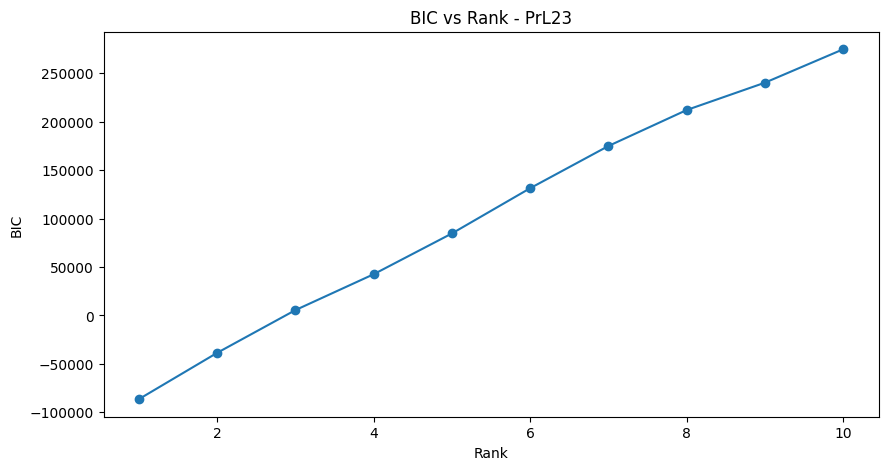

Optimal rank for PrL23: 1

Analyzing PrL5...
PrL5 Processed Gamma Power Shape: (26, 6058)


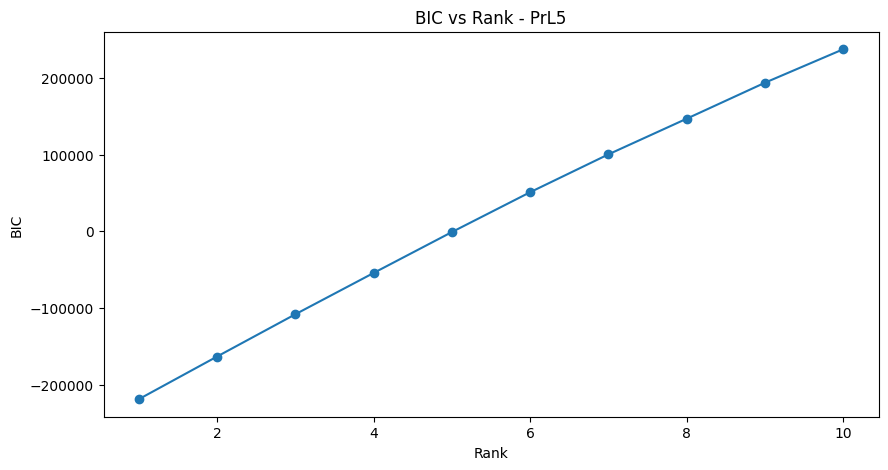

Optimal rank for PrL5: 1


In [12]:
import numpy as np
import tensorly as tl
from tensorly.decomposition import parafac
from scipy.signal import welch
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Enhanced CP decomposition with error handling
def safe_parafac(tensor, rank, max_iter=100, tol=1e-6):
    try:
        factors = parafac(tensor, rank=rank, n_iter_max=max_iter, tol=tol)
        return factors
    except:
        print(f"Warning: CP decomposition failed for rank {rank}, trying with regularization...")
        try:
            # Add small regularization
            factors = parafac(tensor + 1e-6*np.random.randn(*tensor.shape),
                            rank=rank, n_iter_max=max_iter, tol=tol)
            return factors
        except Exception as e:
            print(f"Failed completely for rank {rank}: {str(e)}")
            return None

def num_parameters(rank, tensor_shape):
    return rank * sum(tensor_shape)  # Standard CP parameter count

def bic(n_params, error, n):
    return n_params * np.log(n) + 2 * n * np.log(error + 1e-16)  # Added small constant to avoid log(0)

def analyze_layer(data, layer_name):
    num_channels = data.shape[0]
    gamma_power_matrix = []

    # 1. Compute Gamma Power with preprocessing
    for chan in range(num_channels):
        channel_data = data[chan]
        channel_gamma_power = []

        # Normalize channel data first
        channel_data = (channel_data - np.mean(channel_data)) / np.std(channel_data)

        for start in range(0, len(channel_data) - window_size, stride):
            segment = channel_data[start:start + window_size]
            f, Pxx = welch(segment, fs=target_sf, nperseg=256)
            gamma_power = np.mean(Pxx[(f >= 30) & (f <= 100)])
            channel_gamma_power.append(gamma_power)

        gamma_power_matrix.append(channel_gamma_power)

    # 2. Normalize across channels and time
    gamma_power_array = np.array(gamma_power_matrix)
    gamma_power_array = StandardScaler().fit_transform(gamma_power_array)

    print(f"{layer_name} Processed Gamma Power Shape:", gamma_power_array.shape)

    # 3. CP Decomposition with rank analysis
    tensor_data = tl.tensor(gamma_power_array)
    ranks = range(1, 11)  # More conservative rank range
    results = []

    for rank in ranks:
        factors = safe_parafac(tensor_data, rank)
        if factors is None:
            continue

        reconstructed = tl.cp_to_tensor(factors)
        error = tl.norm(tensor_data - reconstructed) / (tl.norm(tensor_data) + 1e-16)
        n_params = num_parameters(rank, tensor_data.shape)
        bic_val = bic(n_params, error, np.prod(tensor_data.shape))

        results.append({
            'rank': rank,
            'error': error,
            'bic': bic_val,
            'factors': factors
        })

    # Plot results
    if results:
        ranks = [r['rank'] for r in results]
        bic_values = [r['bic'] for r in results]

        plt.figure(figsize=(10, 5))
        plt.plot(ranks, bic_values, 'o-')
        plt.title(f'BIC vs Rank - {layer_name}')
        plt.xlabel('Rank')
        plt.ylabel('BIC')
        plt.show()

        optimal_rank = ranks[np.argmin(bic_values)]
        print(f"Optimal rank for {layer_name}: {optimal_rank}")
        return optimal_rank
    else:
        print(f"All rank attempts failed for {layer_name}")
        return None

# Parameters
target_sf = 1000
window_size = 1000
stride = 500

# Run analysis
print("Analyzing PrL23...")
optimal_prl23 = analyze_layer(PrL23_data, "PrL23")

print("\nAnalyzing PrL5...")
optimal_prl5 = analyze_layer(PrL5_data, "PrL5")

PrL_L23 (13 ch) processed shape: (13, 6058)
PrL_L23 (13 ch) optimal rank: 1
Using raw power for PrL_L23 (13 ch)
PrL_L5 (26 ch) processed shape: (26, 6058)
PrL_L5 (26 ch) optimal rank: 1
Using raw power for PrL_L5 (26 ch)


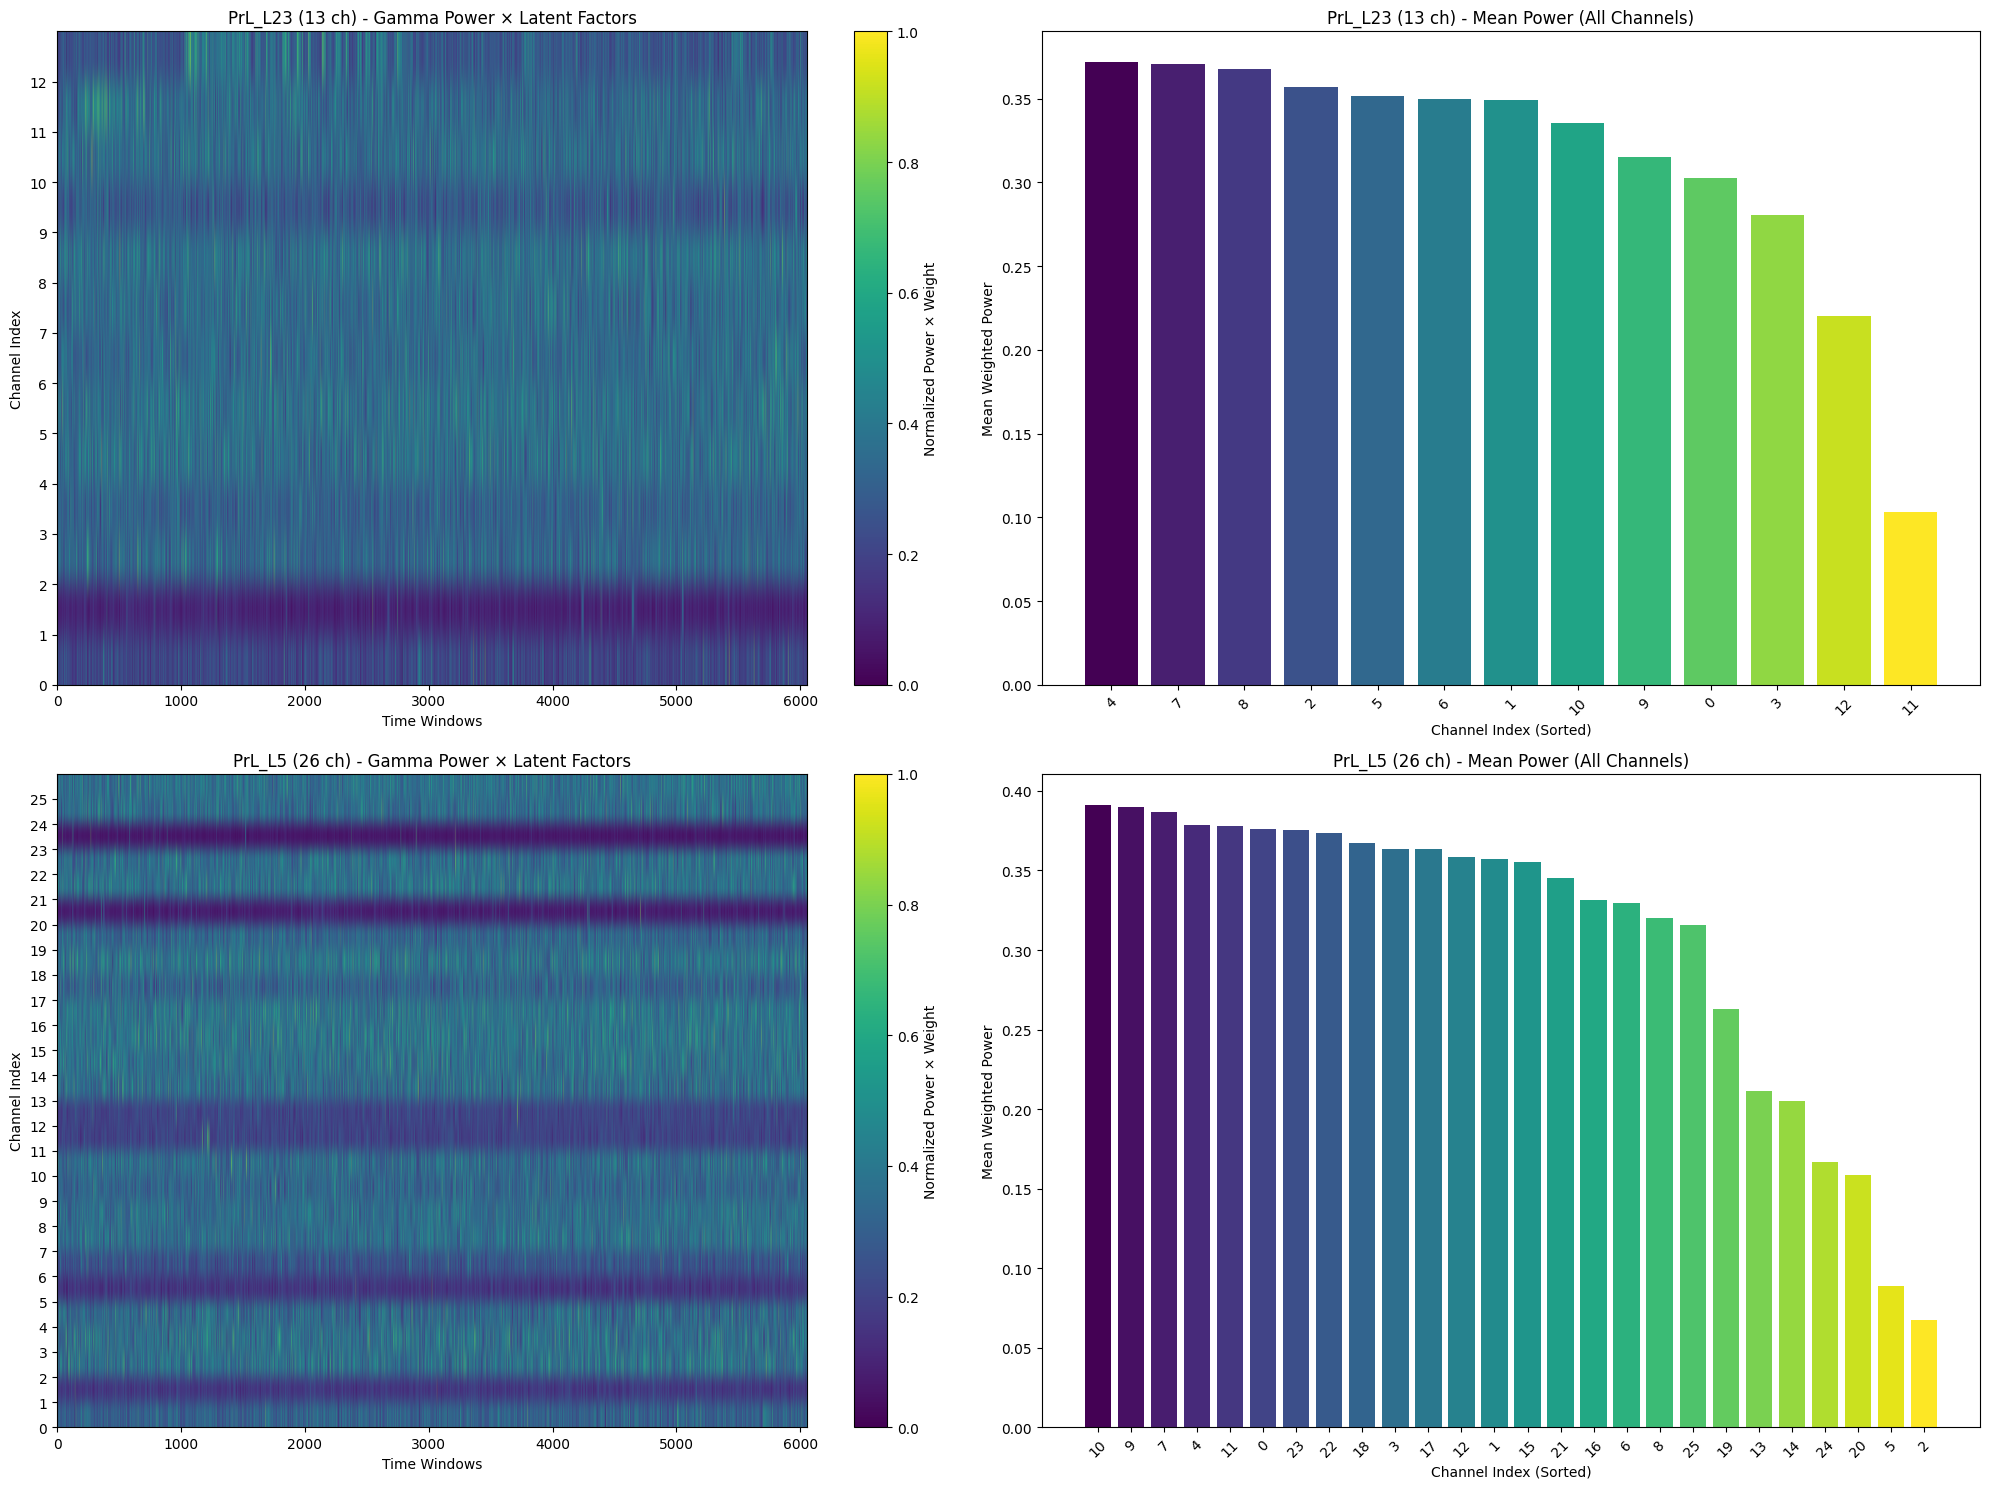

In [13]:
import numpy as np
import tensorly as tl
from tensorly.decomposition import parafac
from scipy.signal import welch
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Parameters
datasets = [PrL23_data, PrL5_data]
dataset_names = ['PrL_L23 (13 ch)', 'PrL_L5 (26 ch)']
window_size, stride = 1000, 500
target_sf = 1000  # Hz
ranks = range(1, 6)  # More conservative rank range for stability

# Initialize storage
combined_power_list = []

# Create figure
fig, axs = plt.subplots(2, 2, figsize=(20, 15))

for i, (data, name) in enumerate(zip(datasets, dataset_names)):
    num_channels = data.shape[0]

    # 1. Gamma Power Calculation (all channels)
    gamma_power_matrix = []
    for chan in range(num_channels):
        channel_power = []
        for start in range(0, data.shape[1] - window_size, stride):
            segment = data[chan, start:start + window_size]
            f, Pxx = welch(segment, fs=target_sf, nperseg=256)
            gamma_power = np.mean(Pxx[(30 <= f) & (f <= 100)])
            channel_power.append(gamma_power)
        gamma_power_matrix.append(channel_power)

    gamma_power_array = np.array(gamma_power_matrix)
    print(f"{name} processed shape: {gamma_power_array.shape}")

    # 2. CP Decomposition with optimal rank selection
    tensor_data = tl.tensor(gamma_power_array)
    n_data_points = np.prod(tensor_data.shape)
    bic_values = []

    for rank in ranks:
        try:
            factors = parafac(tensor_data, rank=rank)
            error = tl.norm(tensor_data - tl.cp_to_tensor(factors)) / (tl.norm(tensor_data) + 1e-16)
            bic_val = bic(rank*(tensor_data.shape[0]+tensor_data.shape[1]), error, n_data_points)
            bic_values.append(bic_val)
        except:
            bic_values.append(np.inf)
            print(f"Rank {rank} failed for {name}")

    optimal_rank = ranks[np.argmin(bic_values)]
    print(f"{name} optimal rank: {optimal_rank}")

    # 3. Compute latent-weighted power
    scaler = MinMaxScaler()
    norm_power = scaler.fit_transform(gamma_power_array.T).T

    try:
        factors = parafac(tl.tensor(norm_power), rank=optimal_rank)
        latent_weights = np.mean(np.abs(factors.factors[1]), axis=1)
        combined_power = norm_power * latent_weights[:, np.newaxis]
    except:
        print(f"Using raw power for {name}")
        combined_power = norm_power

    combined_power_list.append(combined_power)

    # 4. Visualization
    # Heatmap of all channels
    im = axs[i,0].imshow(combined_power, aspect='auto', cmap='viridis',
                        extent=[0, combined_power.shape[1], 0, num_channels])
    axs[i,0].set_title(f"{name} - Gamma Power × Latent Factors")
    axs[i,0].set_xlabel("Time Windows")
    axs[i,0].set_ylabel("Channel Index")
    axs[i,0].set_yticks(np.arange(num_channels))
    fig.colorbar(im, ax=axs[i,0], label="Normalized Power × Weight")

    # Mean power across time
    mean_power = np.mean(combined_power, axis=1)
    ch_order = np.argsort(mean_power)[::-1]  # Sort descending

    axs[i,1].bar(range(num_channels), mean_power[ch_order],
                color=plt.cm.viridis(np.linspace(0,1,num_channels)))
    axs[i,1].set_title(f"{name} - Mean Power (All Channels)")
    axs[i,1].set_xlabel("Channel Index (Sorted)")
    axs[i,1].set_ylabel("Mean Weighted Power")
    axs[i,1].set_xticks(range(num_channels))
    axs[i,1].set_xticklabels(ch_order)
    axs[i,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Access results
combined_power_PrL23_GBO = combined_power_list[0]
combined_power_PrL5_GBO = combined_power_list[1]

PrL_L23 (13 ch) processed shape: (13, 6058)
PrL_L23 (13 ch) optimal rank: 1
Using raw power for PrL_L23 (13 ch)
PrL_L5 (26 ch) processed shape: (26, 6058)
PrL_L5 (26 ch) optimal rank: 1
Using raw power for PrL_L5 (26 ch)


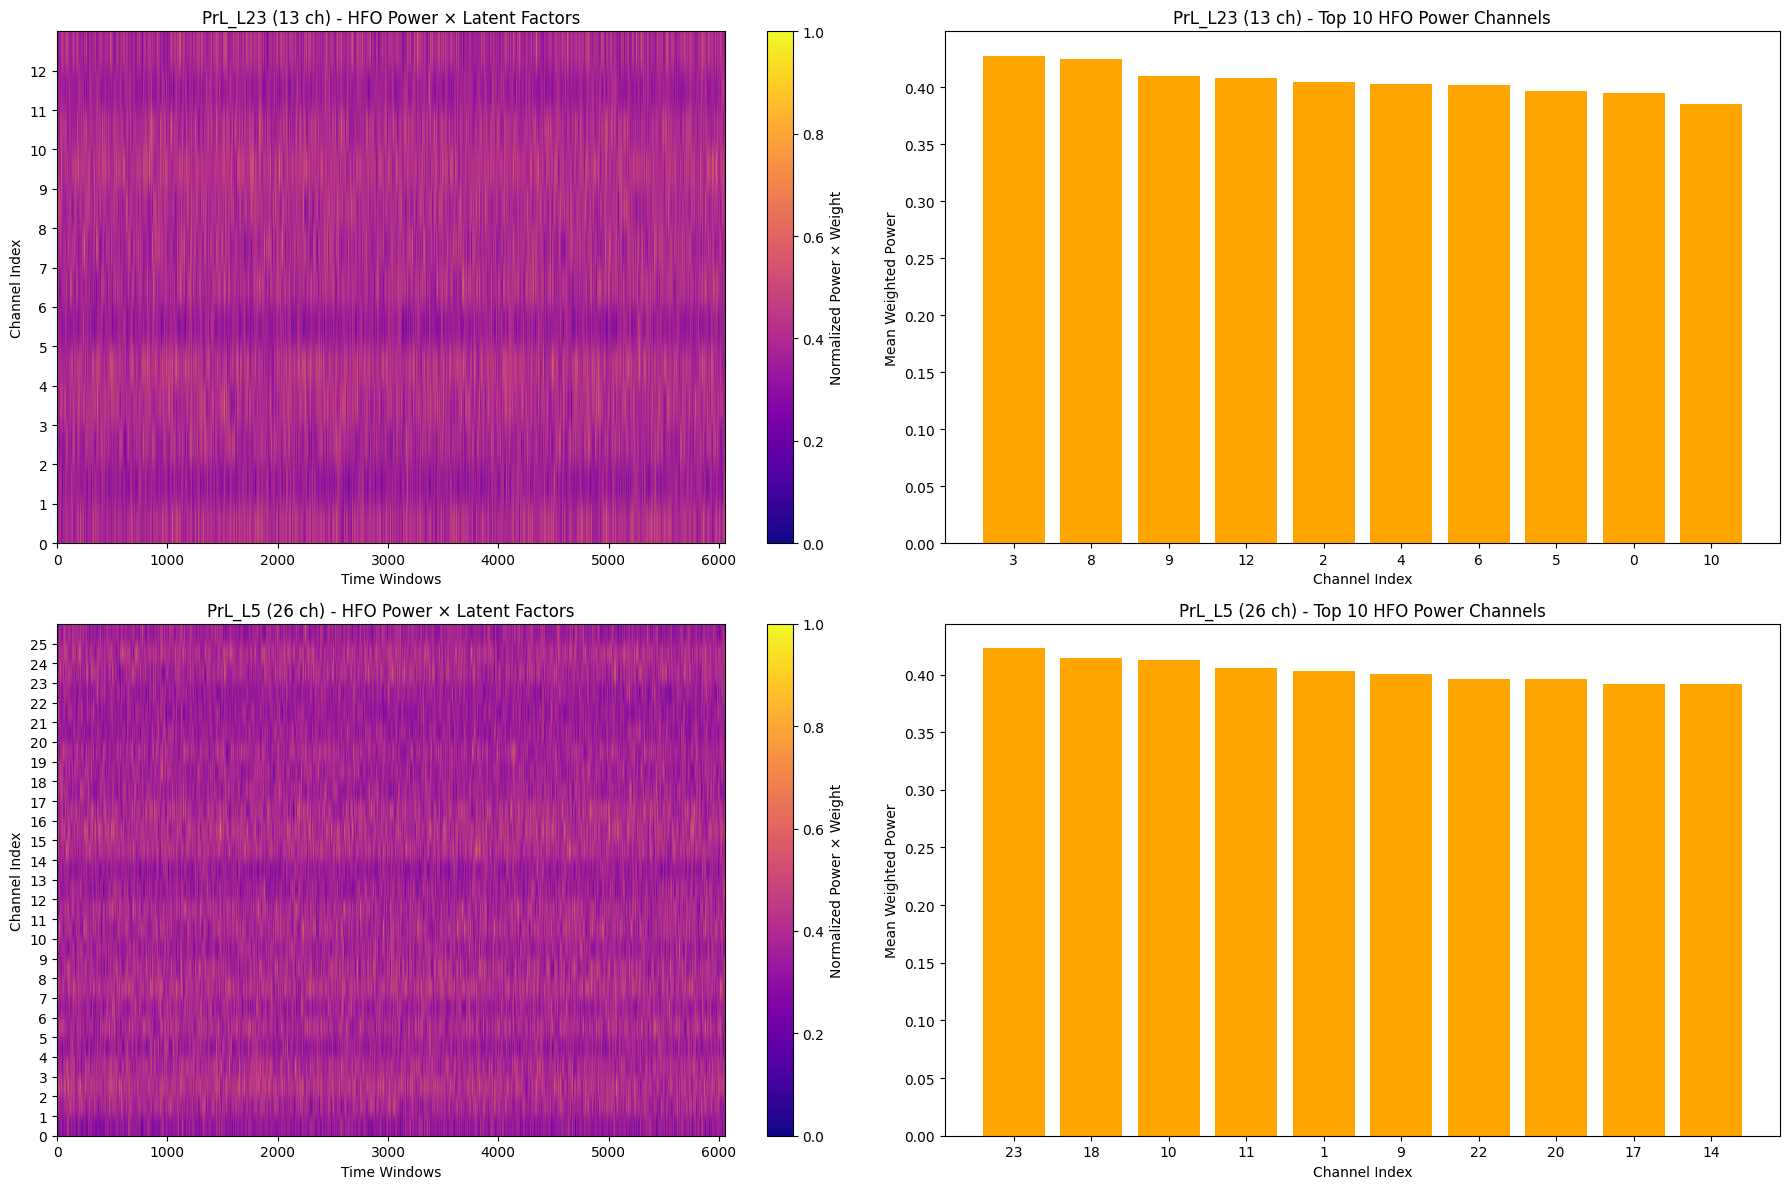

In [14]:
import numpy as np
import tensorly as tl
from tensorly.decomposition import parafac
from scipy.signal import welch
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Parameters
datasets = [PrL23_data, PrL5_data]
dataset_names = ['PrL_L23 (13 ch)', 'PrL_L5 (26 ch)']
window_size, stride = 1000, 500  # 1s windows with 50% overlap
target_sf = 1000  # Hz
ranks = range(1, 6)  # Conservative rank range
hfo_band = (120, 200)  # HFO frequency range

# Initialize storage
combined_power_list = []

# Create figure
fig, axs = plt.subplots(2, 2, figsize=(18, 12))

for i, (data, name) in enumerate(zip(datasets, dataset_names)):
    num_channels = data.shape[0]

    # 1. HFO Power Calculation (all channels)
    hfo_power_matrix = []
    for chan in range(num_channels):
        channel_power = []
        for start in range(0, data.shape[1] - window_size, stride):
            segment = data[chan, start:start + window_size]
            f, Pxx = welch(segment, fs=target_sf, nperseg=256)
            hfo_power = np.mean(Pxx[(f >= hfo_band[0]) & (f <= hfo_band[1])])
            channel_power.append(hfo_power)
        hfo_power_matrix.append(channel_power)

    hfo_power_array = np.array(hfo_power_matrix)
    print(f"{name} processed shape: {hfo_power_array.shape}")

    # 2. CP Decomposition with BIC-based rank selection
    tensor_data = tl.tensor(hfo_power_array)
    n_data_points = np.prod(tensor_data.shape)
    bic_values = []

    for rank in ranks:
        try:
            factors = parafac(tensor_data, rank=rank)
            error = tl.norm(tensor_data - tl.cp_to_tensor(factors)) / (tl.norm(tensor_data) + 1e-16)
            bic_val = bic(rank*(tensor_data.shape[0]+tensor_data.shape[1]), error, n_data_points)
            bic_values.append(bic_val)
        except:
            bic_values.append(np.inf)
            print(f"Rank {rank} failed for {name}")

    optimal_rank = ranks[np.argmin(bic_values)]
    print(f"{name} optimal rank: {optimal_rank}")

    # 3. Compute latent-weighted HFO power
    scaler = MinMaxScaler()
    norm_power = scaler.fit_transform(hfo_power_array.T).T

    try:
        factors = parafac(tl.tensor(norm_power), rank=optimal_rank)
        latent_weights = np.mean(np.abs(factors.factors[1]), axis=1)
        combined_power = norm_power * latent_weights[:, np.newaxis]
    except:
        print(f"Using raw power for {name}")
        combined_power = norm_power

    combined_power_list.append(combined_power)

    # 4. Visualization
    # Heatmap of HFO power × latent factors
    img = axs[i,0].imshow(combined_power, aspect='auto', cmap='plasma',
                         extent=[0, combined_power.shape[1], 0, num_channels])
    axs[i,0].set_title(f"{name} - HFO Power × Latent Factors")
    axs[i,0].set_xlabel("Time Windows")
    axs[i,0].set_ylabel("Channel Index")
    axs[i,0].set_yticks(np.arange(num_channels))
    fig.colorbar(img, ax=axs[i,0], label="Normalized Power × Weight")

    # Mean HFO power across time
    mean_power = np.mean(combined_power, axis=1)
    top_channels = np.argsort(mean_power)[-10:][::-1]  # Top 10 channels

    axs[i,1].bar(range(10), mean_power[top_channels],
                tick_label=top_channels, color='orange')
    axs[i,1].set_title(f"{name} - Top 10 HFO Power Channels")
    axs[i,1].set_xlabel("Channel Index")
    axs[i,1].set_ylabel("Mean Weighted Power")

plt.tight_layout()
plt.show()

# Access results
combined_power_PrL23_HFO = combined_power_list[0]
combined_power_PrL5_HFO = combined_power_list[1]

In [15]:
import os

# --- 1. Mount your Google Drive ---
# This only needs to be done once.
#drive.mount('/content/drive')

# --- 2. Define the shared directory path ---
# All files will be saved here.
directory_path = '/content/drive/MyDrive/ML_Samples/preprocessed_data/KO/'

# Create the directory once if it doesn't exist
#os.makedirs(directory_path, exist_ok=True)


# --- 4. Create a dictionary of filenames and variables ---
# Key: The filename (string)
# Value: The variable you want to save
files_to_save = {
    'Mouse_03_PrL23_GBO.npy': combined_power_PrL23_GBO,
    'Mouse_03_PrL5_GBO.npy': combined_power_PrL5_GBO,
    'Mouse_03_PrL23_HFO.npy': combined_power_PrL23_HFO,
    'Mouse_03_PrL5_HFO.npy': combined_power_PrL5_HFO,
}

# --- 5. Loop through the dictionary and save each file ---
for filename, data in files_to_save.items():
    full_path = os.path.join(directory_path, filename)
    np.save(full_path, data)
    print(f"✅ Saved: {full_path}")

print("\nAll files have been saved successfully! 🎉")

✅ Saved: /content/drive/MyDrive/ML_Samples/preprocessed_data/KO/Mouse_03_PrL23_GBO.npy
✅ Saved: /content/drive/MyDrive/ML_Samples/preprocessed_data/KO/Mouse_03_PrL5_GBO.npy
✅ Saved: /content/drive/MyDrive/ML_Samples/preprocessed_data/KO/Mouse_03_PrL23_HFO.npy
✅ Saved: /content/drive/MyDrive/ML_Samples/preprocessed_data/KO/Mouse_03_PrL5_HFO.npy

All files have been saved successfully! 🎉
